# Trois modèles traditionnels — évaluation reproductible

Ce notebook évalue uniquement et conjointement trois modèles : **régression logistique**, **Naive Bayes multinomial** et **Linear SVC**.

Protocole :

1. Le jeu de test stratifié (20 %) est isolé avant toute validation croisée.
2. Sur le train uniquement, `RepeatedStratifiedKFold` emploie 5 folds répétés 3 fois.
3. Dans chaque fold, seul le sous-train est suréchantillonné avec remise. La validation et le test gardent leur distribution originale.
4. `TfidfVectorizer` est inclus dans chaque `Pipeline`, donc il est ajusté uniquement sur les données d'entraînement du fold. Cela évite la fuite de données.
5. Toutes les sources de hasard et les estimateurs stochastiques reçoivent la même graine (`RANDOM_STATE=42`).

À l'exécution, la cellule « Nettoyage et anonymisation » lit le fichier privé `Facebook_Data_MPox_Modified.xlsx`, applique le nettoyage puis crée automatiquement `Facebook_Data_MPox_anonymized.csv`. Les pages sont pseudonymisées (`Page_001`, etc.), les dates sont ramenées au mois et les identifiants directs sont retirés du texte. Les métriques d'engagement sont conservées afin de reproduire les analyses descriptives du notebook original.



In [ ]:
import os
import random
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.utils import resample


# ============================================================
# 1. Paramètres et reproductibilité
# ============================================================
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_REPEATS = 3
SOURCE_DATA_PATH = "Facebook_Data_MPox_Modified.xlsx"
ANONYMIZED_DATA_PATH = "Facebook_Data_MPox_anonymized.csv"


def set_global_seed(seed):
    """Fixe les générateurs aléatoires utilisés dans ce notebook."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)


set_global_seed(RANDOM_STATE)
print(f"Python : {platform.python_version()} | scikit-learn : {sklearn.__version__}")
print(f"pandas : {pd.__version__} | numpy : {np.__version__}")


# ============================================================


Python : 3.13.15 | scikit-learn : 1.6.1
pandas : 2.2.3 | numpy : 2.1.3


In [ ]:
# ============================================================
# 2. Nettoyage, anonymisation et export GitHub
# ============================================================
# Le CSV anonymisé est
# créé après le nettoyage et peut être publié.
if Path(SOURCE_DATA_PATH).exists():
    raw_df = pd.read_excel(SOURCE_DATA_PATH)
    required_columns = {"Texte", "categorie"}
    missing_columns = required_columns.difference(raw_df.columns)
    if missing_columns:
        raise ValueError(f"Colonnes manquantes dans le fichier source : {sorted(missing_columns)}")

    text = raw_df["Texte"].fillna("").astype(str)
    text = text.str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
    text = text.str.replace(r"[\w.+-]+@[\w-]+\.[\w.-]+", " ", regex=True)
    text = text.str.replace(r"(?<!\w)@[\w_]+", " ", regex=True)
    text = text.str.replace(r"\+?\d[\d\s().-]{6,}\d", " ", regex=True)
    text = text.str.lower()
    text = text.str.replace(r"[^a-zA-ZÀ-ÿ\s]", " ", regex=True)
    text = text.str.replace(r"\s+", " ", regex=True).str.strip()

    page_source = raw_df.get("PageName", pd.Series("Page inconnue", index=raw_df.index))
    page_source = page_source.fillna("Page inconnue").astype(str)
    page_codes = {
        page: f"Page_{number:03d}"
        for number, page in enumerate(sorted(page_source.unique()), start=1)
    }
    date_month = pd.to_datetime(raw_df.get("Date"), errors="coerce").dt.to_period("M").dt.to_timestamp()

    df = pd.DataFrame({
        "Date": date_month,
        "Page_anonymisee": page_source.map(page_codes),
        "Texte_anonymise": text,
        "likes": pd.to_numeric(raw_df.get("likes", 0), errors="coerce").fillna(0),
        "Partages": pd.to_numeric(raw_df.get("Partages", 0), errors="coerce").fillna(0),
        "commentaires": pd.to_numeric(raw_df.get("commentaires", 0), errors="coerce").fillna(0),
        "engagement": pd.to_numeric(raw_df.get("engagement", 0), errors="coerce").fillna(0),
        "categorie": pd.to_numeric(raw_df["categorie"], errors="raise").astype(int),
    })
    df = df.dropna(subset=["categorie"])
    df = df[df["Texte_anonymise"].ne("")].reset_index(drop=True)
    if set(df["categorie"].unique()) != {0, 1}:
        raise ValueError("La colonne 'categorie' doit contenir exactement les classes 0 et 1.")
    df["categorie_nom"] = df["categorie"].map({0: "Informatif", 1: "Alarmiste"})
    df.to_csv(ANONYMIZED_DATA_PATH, index=False, encoding="utf-8-sig")
    print(f"CSV anonymisé créé : {ANONYMIZED_DATA_PATH}")
else:
    # Aucune donnée privée n'est requise quand le CSV est déjà présent.
    if not Path(ANONYMIZED_DATA_PATH).exists():
        raise FileNotFoundError(
            f"Ajoutez soit {SOURCE_DATA_PATH}, soit {ANONYMIZED_DATA_PATH} dans ce dossier."
        )
    df = pd.read_csv(ANONYMIZED_DATA_PATH, encoding="utf-8-sig")
    print(f"CSV anonymisé réutilisé : {ANONYMIZED_DATA_PATH}")

required_columns = {"Texte_anonymise", "categorie"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colonnes manquantes : {sorted(missing_columns)}")
df = df.dropna(subset=["Texte_anonymise", "categorie"]).copy()
df["Texte_anonymise"] = df["Texte_anonymise"].astype(str).str.strip()
df = df[df["Texte_anonymise"].ne("")].copy()
df["categorie"] = pd.to_numeric(df["categorie"], errors="raise").astype(int)

X = df["Texte_anonymise"].reset_index(drop=True)
y = df["categorie"].reset_index(drop=True)
if y.value_counts().min() < N_SPLITS:
    raise ValueError(f"La classe minoritaire contient moins de {N_SPLITS} observations.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print("\nDistribution train :")
print(y_train.value_counts().sort_index())
print("\nDistribution test hold-out :")
print(y_test.value_counts().sort_index())


CSV anonymisé créé : Facebook_Data_MPox_anonymized.csv

Distribution train :
categorie
0    256
1     29
Name: count, dtype: int64

Distribution test hold-out :
categorie
0    65
1     7
Name: count, dtype: int64



VALIDATION CROISÉE — 5 folds × 3 répétitions
                        accuracy         precision_alarmiste          \
                            mean     std                mean     std   
model                                                                  
Linear SVC                0.9251  0.0269              0.7644  0.2247   
Logistic Regression       0.9251  0.0314              0.7422  0.2421   
Multinomial Naive Bayes   0.8947  0.0351              0.5009  0.0991   

                        recall_alarmiste         f1_alarmiste          \
                                    mean     std         mean     std   
model                                                                   
Linear SVC                        0.4133  0.1608       0.5203  0.1763   
Logistic Regression               0.4356  0.1716       0.5370  0.1841   
Multinomial Naive Bayes           0.7844  0.1463       0.6061  0.1023   

                        f1_macro          
                            mean     st

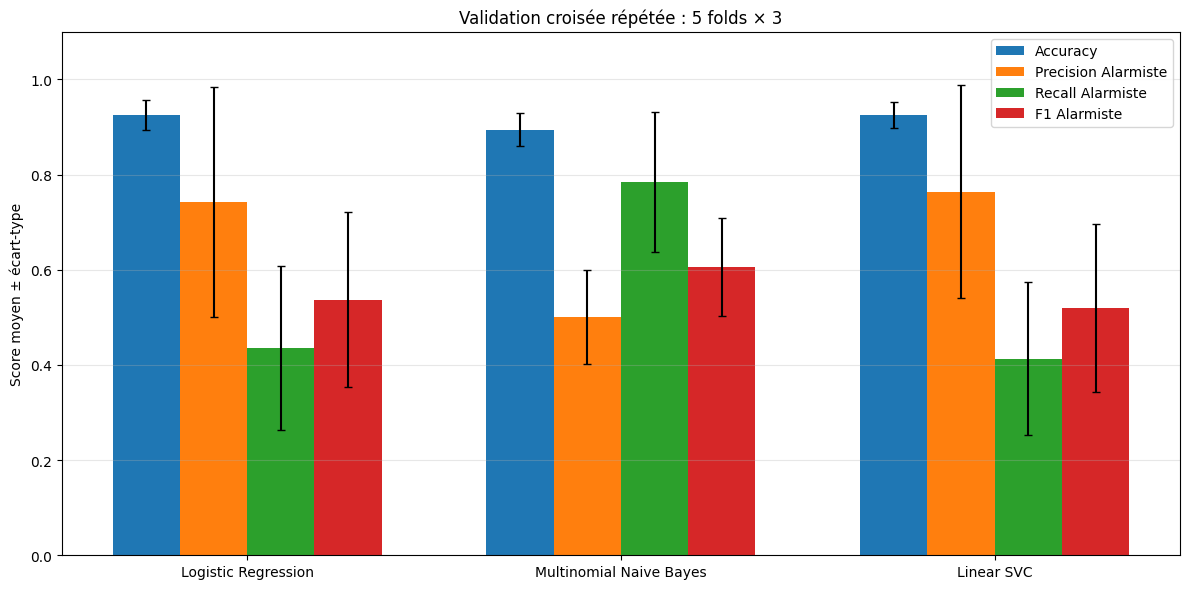

/tmp/ipykernel_6482/1976553847.py:192: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


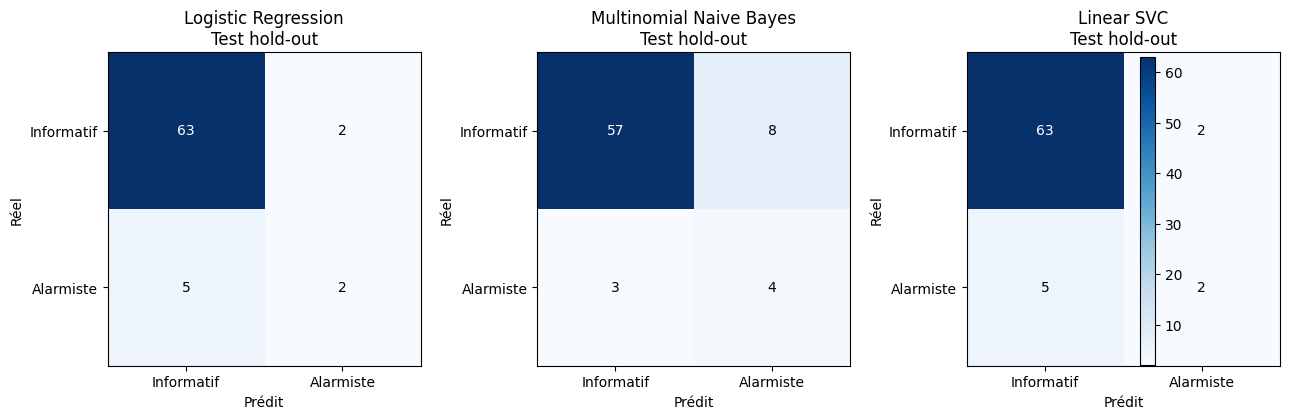

In [ ]:
# 3. Suréchantillonnage seulement sur les sous-trains
# ============================================================
def oversample_training_fold(X_fold, y_fold, random_state):
    """Équilibre les classes avec remise, sans toucher à la validation/test."""
    fold_df = pd.DataFrame({"text": list(X_fold), "label": list(y_fold)})
    class_counts = fold_df["label"].value_counts()
    target_n = class_counts.max()
    balanced_parts = []
    for label, group in fold_df.groupby("label", sort=True):
        balanced_parts.append(
            resample(
                group,
                replace=True,
                n_samples=target_n,
                random_state=random_state + int(label),
            )
        )
    balanced = pd.concat(balanced_parts, ignore_index=True).sample(
        frac=1, random_state=random_state
    ).reset_index(drop=True)
    return balanced["text"], balanced["label"]


# Les trois classifieurs sont les seules variantes. La vectorisation et le
# protocole d'évaluation passent par la même fabrique de pipeline.
CLASSIFIERS = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE
    ),
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0),
    "Linear SVC": LinearSVC(
        class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE
    ),
}


def build_pipeline(classifier):
    """Construit le même pipeline TF-IDF pour le classifieur demandé."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000, ngram_range=(1, 2), sublinear_tf=True
        )),
        ("clf", clone(classifier)),
    ])


def compute_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_informatif": precision[0],
        "recall_informatif": recall[0],
        "f1_informatif": f1[0],
        "precision_alarmiste": precision[1],
        "recall_alarmiste": recall[1],
        "f1_alarmiste": f1[1],
        "precision_macro": precision.mean(),
        "recall_macro": recall.mean(),
        "f1_macro": f1.mean(),
    }


# ============================================================
# 4. Repeated Stratified CV, commune aux trois modèles
# ============================================================
cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE
)
cv_rows = []

for fold_id, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    X_fold_train, y_fold_train = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_fold_val, y_fold_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
    X_balanced, y_balanced = oversample_training_fold(
        X_fold_train, y_fold_train, random_state=RANDOM_STATE + fold_id * 100
    )

    for model_name, classifier in CLASSIFIERS.items():
        model = build_pipeline(classifier)
        model.fit(X_balanced, y_balanced)
        y_val_pred = model.predict(X_fold_val)
        cv_rows.append({
            "model": model_name,
            "fold": fold_id,
            **compute_metrics(y_fold_val, y_val_pred),
        })

cv_results = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results.groupby("model")[[
        "accuracy", "precision_alarmiste", "recall_alarmiste",
        "f1_alarmiste", "f1_macro"
    ]]
    .agg(["mean", "std"])
    .round(4)
)

print("\n" + "=" * 76)
print(f"VALIDATION CROISÉE — {N_SPLITS} folds × {N_REPEATS} répétitions")
print("=" * 76)
print(cv_summary)

cv_results.to_csv("traditional_models_repeated_cv_results.csv", index=False, encoding="utf-8-sig")


# ============================================================
# 5. Entraînement final conjoint, puis une seule évaluation test
# ============================================================
X_train_balanced, y_train_balanced = oversample_training_fold(
    X_train, y_train, random_state=RANDOM_STATE
)
test_rows, test_predictions, test_confusions = [], {}, {}

for model_name, classifier in CLASSIFIERS.items():
    final_model = build_pipeline(classifier)
    final_model.fit(X_train_balanced, y_train_balanced)
    y_test_pred = final_model.predict(X_test)
    test_predictions[model_name] = y_test_pred
    test_confusions[model_name] = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
    test_rows.append({"model": model_name, **compute_metrics(y_test, y_test_pred)})

    print("\n" + "=" * 76)
    print(f"TEST HOLD-OUT — {model_name}")
    print("=" * 76)
    print(classification_report(
        y_test, y_test_pred,
        labels=[0, 1],
        target_names=["Informatif", "Alarmiste"],
        zero_division=0,
    ))
    print("Matrice de confusion :")
    print(test_confusions[model_name])

test_summary = pd.DataFrame(test_rows).set_index("model").round(4)
print("\nRÉSUMÉ — TEST HOLD-OUT (non rééchantillonné)")
print(test_summary)
test_summary.to_csv("traditional_models_test_summary.csv", encoding="utf-8-sig")

predictions_export = pd.DataFrame({
    "index_test": np.arange(len(y_test)),
    "categorie_reelle": y_test.to_numpy(),
})
for model_name, predictions in test_predictions.items():
    safe_name = model_name.lower().replace(" ", "_")
    predictions_export[f"prediction_{safe_name}"] = predictions
predictions_export.to_csv(
    "traditional_models_test_predictions.csv", index=False, encoding="utf-8-sig"
)


# ============================================================
# 6. Visualisation : moyenne CV ± écart-type et test final
# ============================================================
plot_metrics = ["accuracy", "precision_alarmiste", "recall_alarmiste", "f1_alarmiste"]
model_names = list(CLASSIFIERS)
positions = np.arange(len(model_names))
width = 0.18

fig, ax = plt.subplots(figsize=(12, 6))
for i, metric in enumerate(plot_metrics):
    means = [cv_results.loc[cv_results["model"] == name, metric].mean() for name in model_names]
    stds = [cv_results.loc[cv_results["model"] == name, metric].std() for name in model_names]
    ax.bar(positions + i * width, means, width, yerr=stds, capsize=3,
           label=metric.replace("_", " ").title())
ax.set_xticks(positions + width * 1.5)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 1.10)
ax.set_ylabel("Score moyen ± écart-type")
ax.set_title(f"Validation croisée répétée : {N_SPLITS} folds × {N_REPEATS}")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("traditional_models_repeated_cv.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, model_name in zip(axes, model_names):
    cm = test_confusions[model_name]
    image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(f"{model_name}\nTest hold-out")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_xticks([0, 1], ["Informatif", "Alarmiste"])
    ax.set_yticks([0, 1], ["Informatif", "Alarmiste"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.04)
plt.tight_layout()
plt.savefig("traditional_models_test_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================


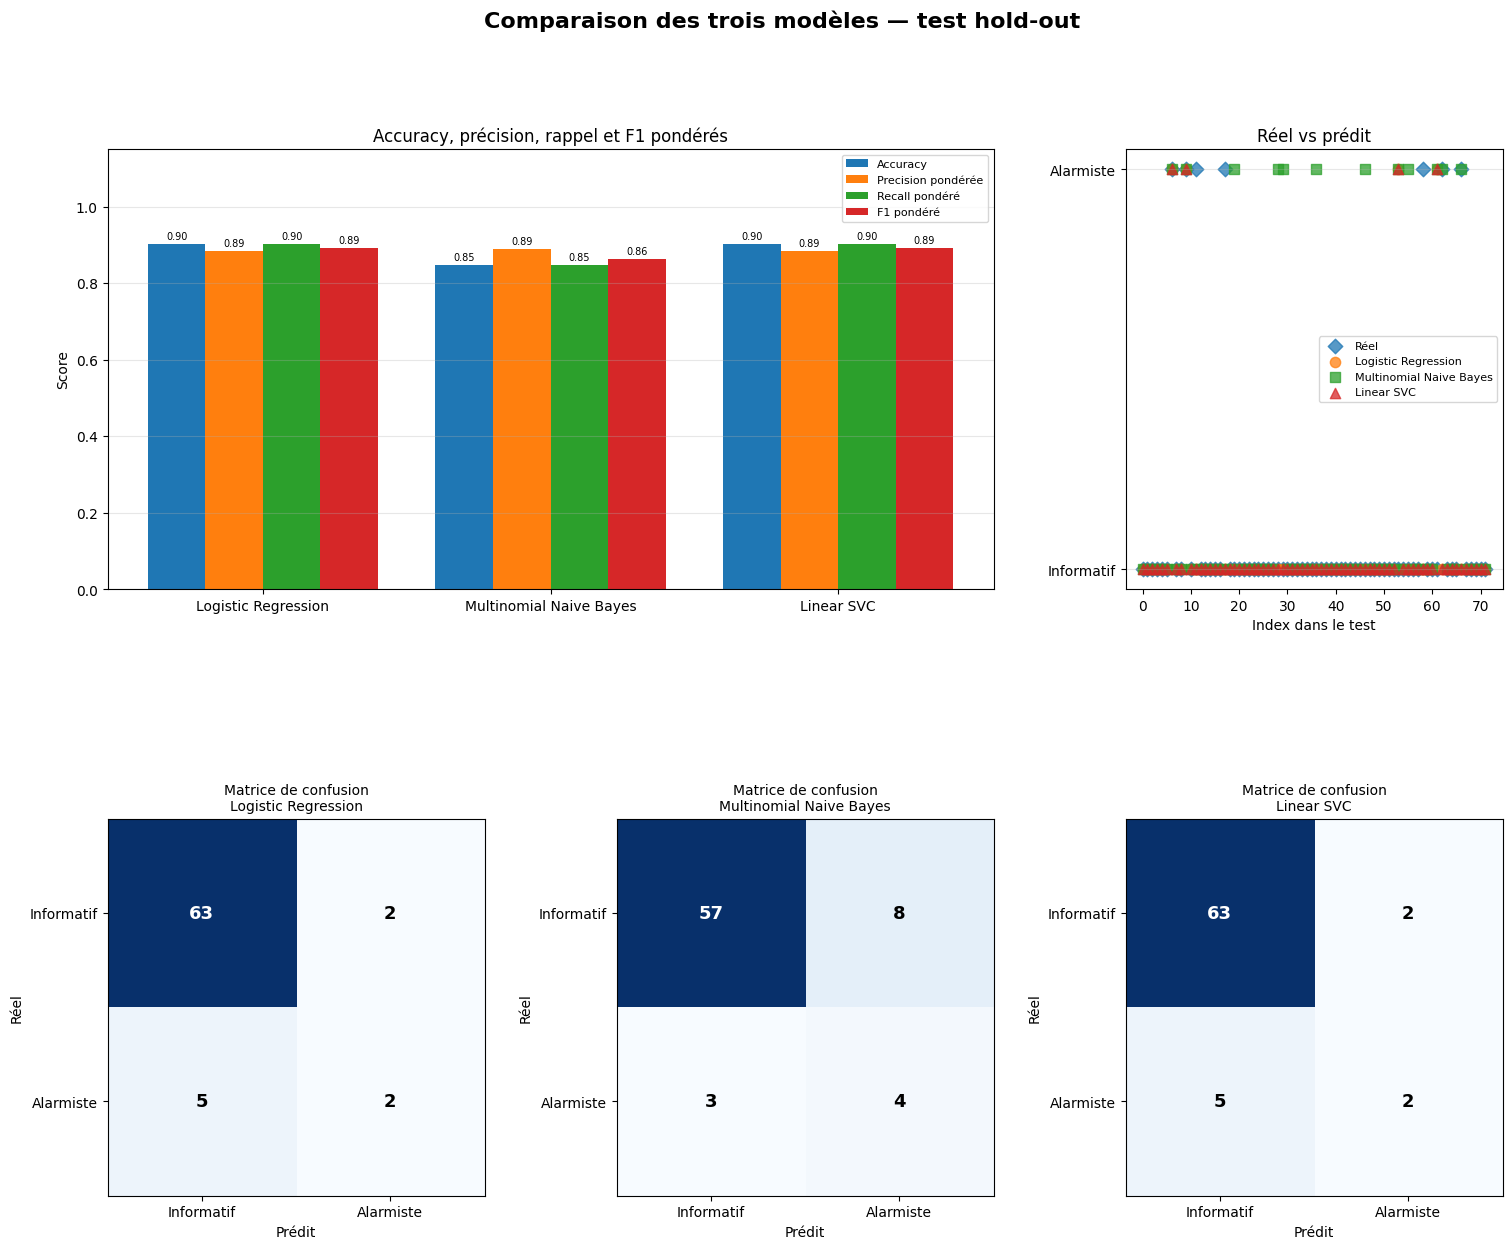

In [ ]:
# 7. Diagnostics comparatifs des trois modèles sur le test final
# ============================================================
test_metric_values = {
    "Accuracy": [accuracy_score(y_test, test_predictions[name]) for name in model_names],
    "Precision pondérée": [
        precision_recall_fscore_support(y_test, test_predictions[name], average="weighted", zero_division=0)[0]
        for name in model_names
    ],
    "Recall pondéré": [
        precision_recall_fscore_support(y_test, test_predictions[name], average="weighted", zero_division=0)[1]
        for name in model_names
    ],
    "F1 pondéré": [
        precision_recall_fscore_support(y_test, test_predictions[name], average="weighted", zero_division=0)[2]
        for name in model_names
    ],
}

fig = plt.figure(figsize=(18, 14))
fig.suptitle("Comparaison des trois modèles — test hold-out", fontsize=16, fontweight="bold", y=0.98)
grid = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

ax_metrics = fig.add_subplot(grid[0, :2])
x = np.arange(len(model_names))
width = 0.20
for i, (metric_name, values) in enumerate(test_metric_values.items()):
    bars = ax_metrics.bar(x + i * width, values, width, label=metric_name)
    ax_metrics.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)
ax_metrics.set_xticks(x + width * 1.5)
ax_metrics.set_xticklabels(model_names)
ax_metrics.set_ylim(0, 1.15)
ax_metrics.set_ylabel("Score")
ax_metrics.set_title("Accuracy, précision, rappel et F1 pondérés")
ax_metrics.legend(fontsize=8)
ax_metrics.grid(axis="y", alpha=0.3)

ax_predictions = fig.add_subplot(grid[0, 2])
sample_index = np.arange(len(y_test))
series_to_plot = {"Réel": y_test.to_numpy(), **test_predictions}
markers = ["D", "o", "s", "^"]
for (label, values), marker in zip(series_to_plot.items(), markers):
    ax_predictions.scatter(sample_index, values, label=label, marker=marker, s=55, alpha=0.75)
ax_predictions.set_yticks([0, 1], ["Informatif", "Alarmiste"])
ax_predictions.set_xlabel("Index dans le test")
ax_predictions.set_title("Réel vs prédit")
ax_predictions.legend(fontsize=8)
ax_predictions.grid(axis="y", alpha=0.3)

for index, model_name in enumerate(model_names):
    ax = fig.add_subplot(grid[1, index])
    cm = test_confusions[model_name]
    ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(f"Matrice de confusion\n{model_name}", fontsize=10)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_xticks([0, 1], ["Informatif", "Alarmiste"])
    ax.set_yticks([0, 1], ["Informatif", "Alarmiste"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black",
                    fontsize=13, fontweight="bold")
plt.savefig("comparaison_trois_modeles_test.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================



Chargement du modèle de sentiment...


config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Analyse de sentiment en cours...

Répartition des sentiments :
sentiment_label
positif    312
négatif     37
neutre       8
Name: count, dtype: int64


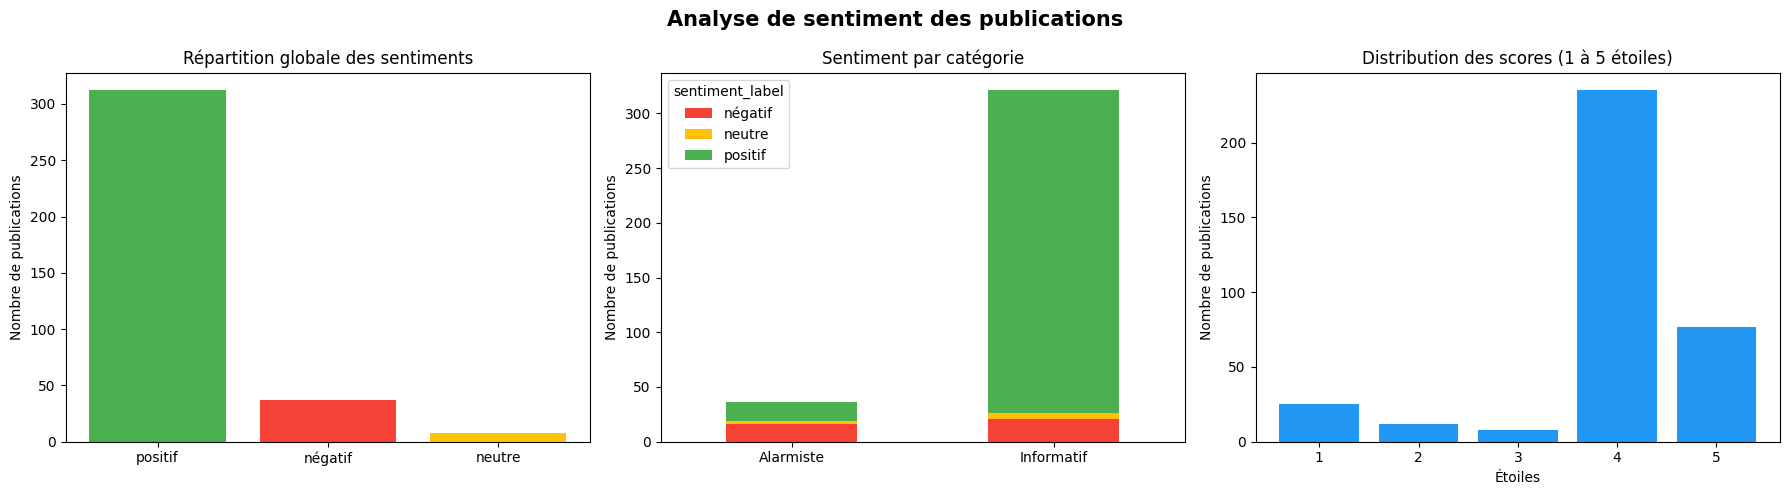

In [ ]:
# 8. Analyse de sentiment (même logique que le notebook original)
# ============================================================

try:
    from transformers import pipeline as hf_pipeline
except ImportError as error:
    raise ImportError(
        "Installez d'abord les dépendances : pip install transformers torch"
    ) from error

print("\nChargement du modèle de sentiment...")
sentiment_analyzer = hf_pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
)


def get_sentiment(text, analyzer=sentiment_analyzer):
    """Convertit les notes 1--5 étoiles en négatif, neutre ou positif."""
    if not str(text).strip():
        return pd.Series({"sentiment_label": "neutre", "sentiment_score": 0.0, "sentiment_stars": 3})
    result = analyzer(str(text)[:512], truncation=True)[0]
    stars = int(result["label"][0])
    label = "négatif" if stars <= 2 else "neutre" if stars == 3 else "positif"
    return pd.Series({
        "sentiment_label": label,
        "sentiment_score": result["score"],
        "sentiment_stars": stars,
    })


print("Analyse de sentiment en cours...")
sentiment_results = df["Texte_anonymise"].apply(get_sentiment)
df = pd.concat([df, sentiment_results], axis=1)
print("\nRépartition des sentiments :")
print(df["sentiment_label"].value_counts())

sentiment_colors = {"positif": "#4CAF50", "neutre": "#FFC107", "négatif": "#F44336"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Analyse de sentiment des publications", fontsize=15, fontweight="bold")

sentiment_counts = df["sentiment_label"].value_counts()
axes[0].bar(sentiment_counts.index, sentiment_counts.values,
            color=[sentiment_colors.get(value, "#999999") for value in sentiment_counts.index])
axes[0].set_title("Répartition globale des sentiments")
axes[0].set_ylabel("Nombre de publications")

cross_sentiment = pd.crosstab(df["categorie_nom"], df["sentiment_label"])
sentiment_order = [value for value in ["négatif", "neutre", "positif"] if value in cross_sentiment.columns]
cross_sentiment.reindex(columns=sentiment_order).plot(
    kind="bar", stacked=True, ax=axes[1],
    color=[sentiment_colors[value] for value in sentiment_order],
)
axes[1].set_title("Sentiment par catégorie")
axes[1].set_xlabel("")
axes[1].set_ylabel("Nombre de publications")
axes[1].tick_params(axis="x", rotation=0)

star_counts = df["sentiment_stars"].value_counts().sort_index()
axes[2].bar(star_counts.index.astype(str), star_counts.values, color="#2196F3")
axes[2].set_title("Distribution des scores (1 à 5 étoiles)")
axes[2].set_xlabel("Étoiles")
axes[2].set_ylabel("Nombre de publications")
plt.tight_layout()
plt.savefig("analyse_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()


# ============================================================



Statistiques descriptives de l'engagement :
             likes    Partages  commentaires   Engagement  Engagement_pondere
count   357.000000  357.000000    357.000000   357.000000          357.000000
mean     68.605042   13.070028      3.050420    84.725490          103.896359
std     241.223912   40.394795     11.060494   260.781901          292.531556
min       2.000000    0.000000      0.000000     2.000000            2.000000
25%      12.000000    0.000000      0.000000    13.000000           15.000000
50%      19.000000    1.000000      1.000000    22.000000           25.000000
75%      34.000000    2.000000      2.000000    41.000000           45.000000
max    3800.000000  214.000000    122.000000  3818.000000         3850.000000


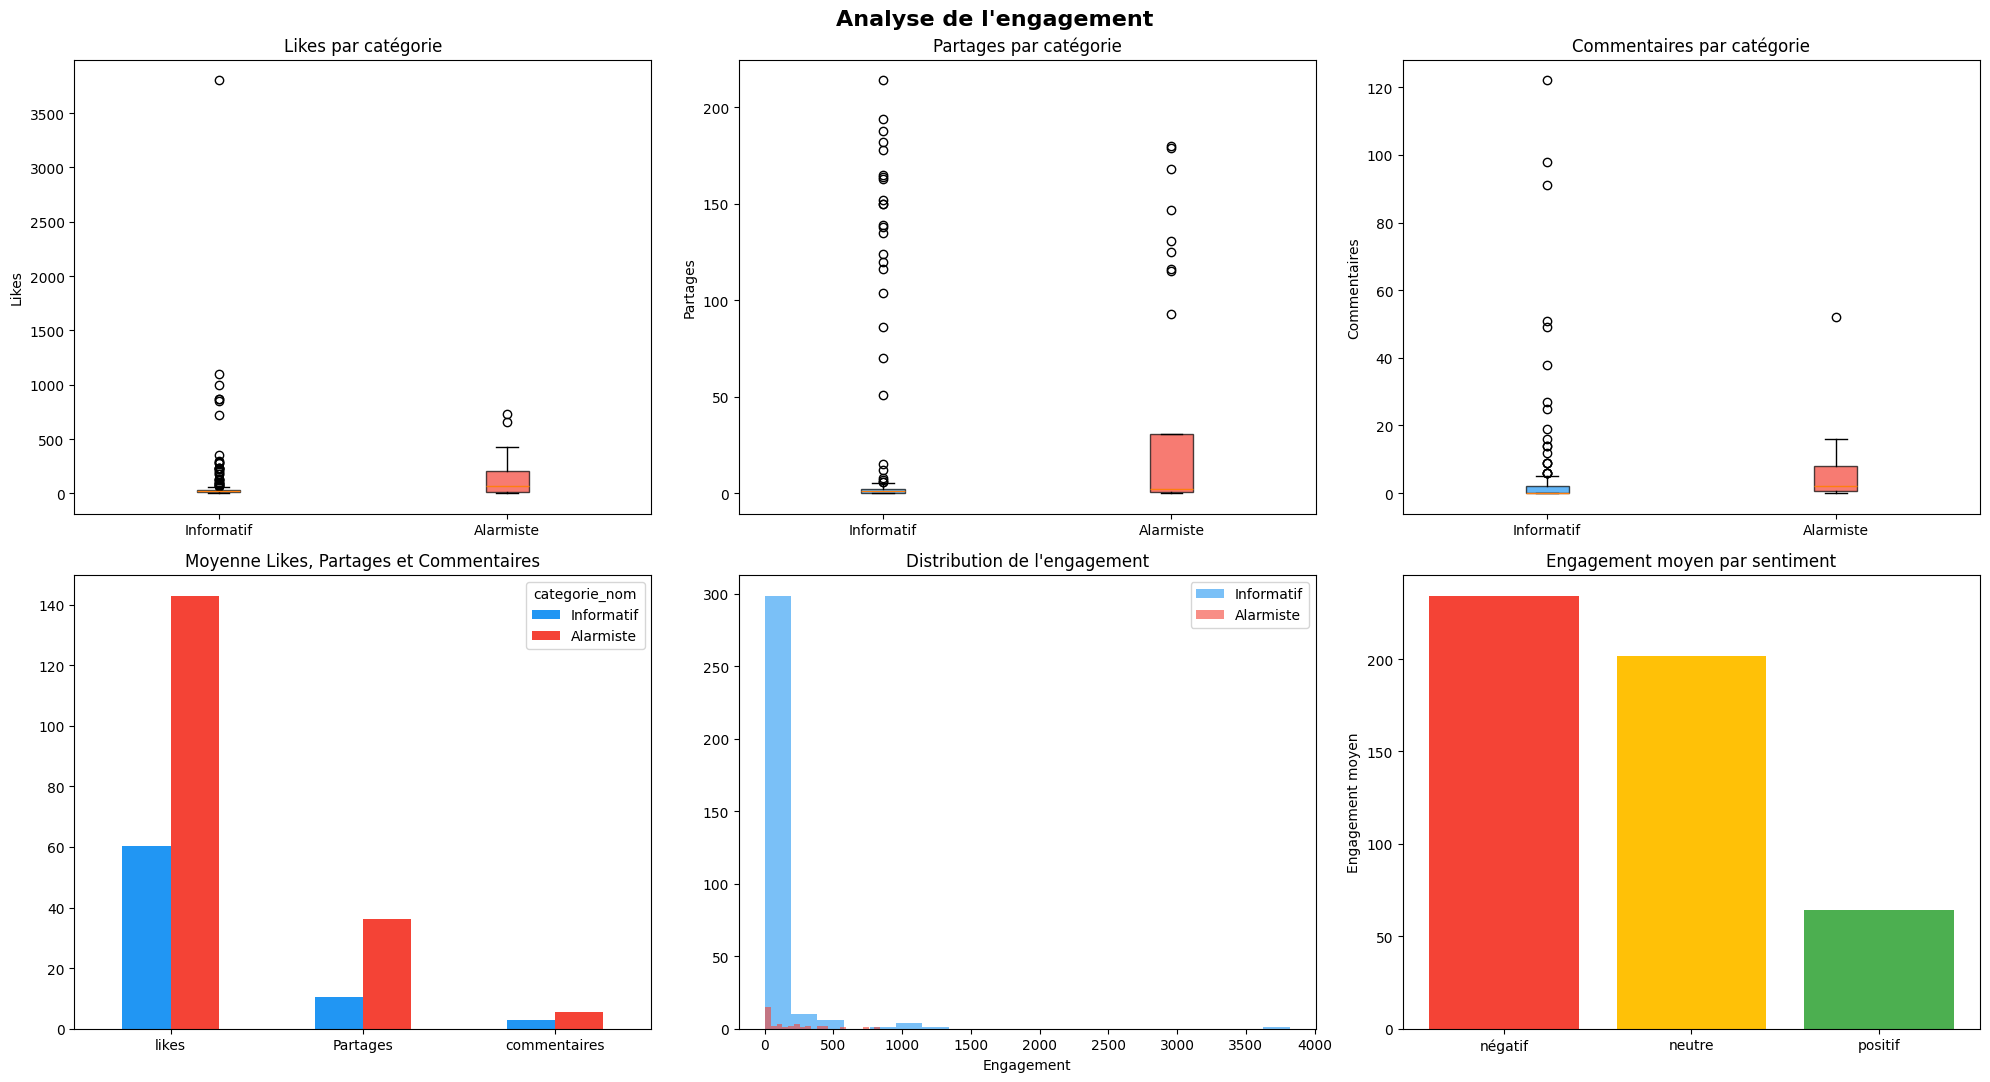

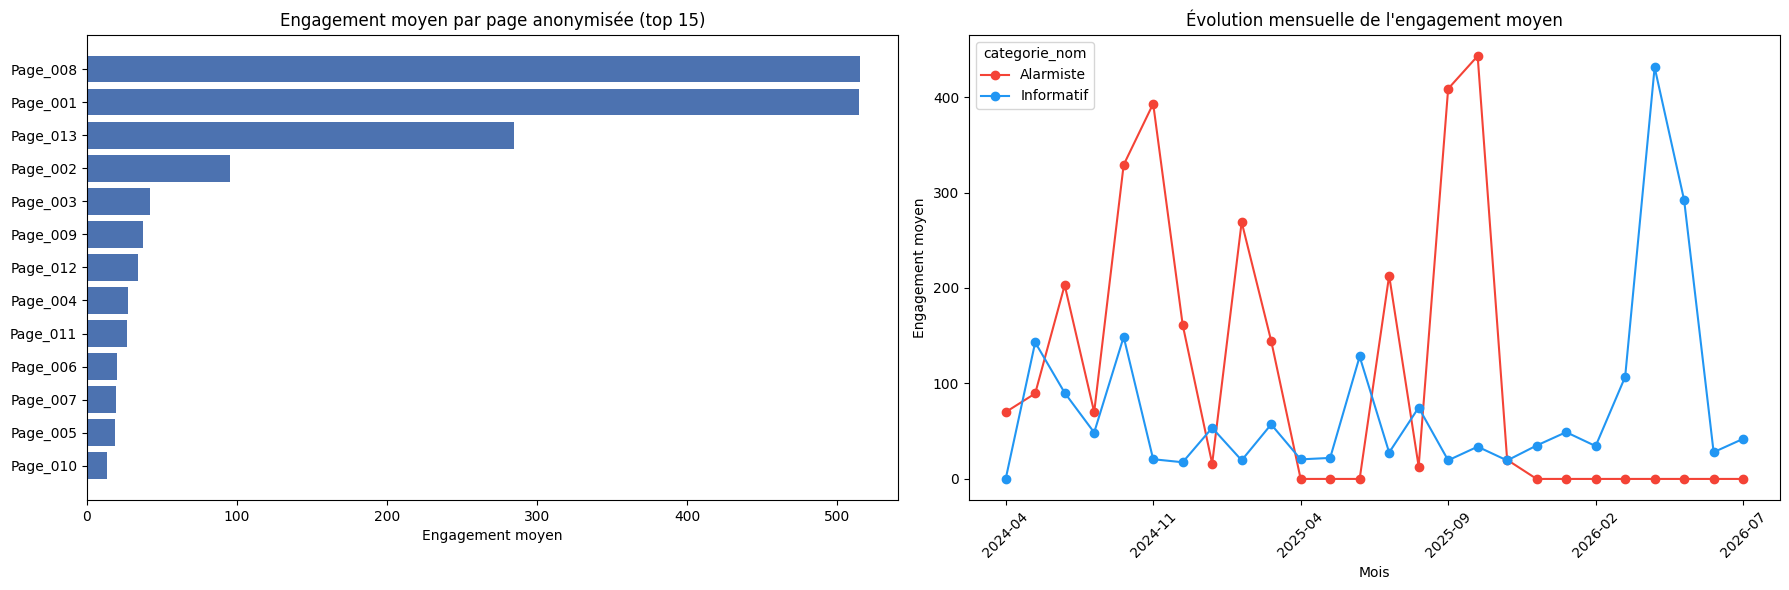


Analyses terminées : performances, sentiment et engagement.


In [ ]:
# 9. Engagement, pages anonymisées et évolution mensuelle
# ============================================================
for column in ["likes", "Partages", "commentaires", "engagement"]:
    df[column] = pd.to_numeric(df[column], errors="coerce").fillna(0)

df["Engagement"] = df["engagement"]
df["Engagement_pondere"] = df["likes"] + 2 * df["Partages"] + 3 * df["commentaires"]
print("\nStatistiques descriptives de l'engagement :")
print(df[["likes", "Partages", "commentaires", "Engagement", "Engagement_pondere"]].describe())

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Analyse de l'engagement", fontsize=16, fontweight="bold")
engagement_columns = [("Likes", "likes"), ("Partages", "Partages"), ("Commentaires", "commentaires")]
for i, (label, column) in enumerate(engagement_columns):
    data_to_plot = [
        df.loc[df["categorie_nom"] == category, column]
        for category in ["Informatif", "Alarmiste"]
    ]
    bp = axes[0, i].boxplot(data_to_plot, tick_labels=["Informatif", "Alarmiste"], patch_artist=True)
    for patch, color in zip(bp["boxes"], ["#2196F3", "#F44336"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[0, i].set_title(f"{label} par catégorie")
    axes[0, i].set_ylabel(label)

mean_by_category = df.groupby("categorie_nom")[["likes", "Partages", "commentaires"]].mean().reindex(
    ["Informatif", "Alarmiste"]
)
mean_by_category.T.plot(kind="bar", ax=axes[1, 0], color=["#2196F3", "#F44336"])
axes[1, 0].set_title("Moyenne Likes, Partages et Commentaires")
axes[1, 0].set_xlabel("")
axes[1, 0].tick_params(axis="x", rotation=0)

for category, color in [("Informatif", "#2196F3"), ("Alarmiste", "#F44336")]:
    axes[1, 1].hist(df.loc[df["categorie_nom"] == category, "Engagement"], bins=20,
                    alpha=0.6, label=category, color=color)
axes[1, 1].set_title("Distribution de l'engagement")
axes[1, 1].set_xlabel("Engagement")
axes[1, 1].legend()

engagement_by_sentiment = df.groupby("sentiment_label")["Engagement"].mean().reindex(sentiment_order)
axes[1, 2].bar(engagement_by_sentiment.index, engagement_by_sentiment.values,
               color=[sentiment_colors[value] for value in engagement_by_sentiment.index])
axes[1, 2].set_title("Engagement moyen par sentiment")
axes[1, 2].set_ylabel("Engagement moyen")
plt.tight_layout()
plt.savefig("analyse_engagement.png", dpi=150, bbox_inches="tight")
plt.show()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
page_engagement = df.groupby("Page_anonymisee")["Engagement"].mean().sort_values(ascending=False).head(15)
axes[0].barh(page_engagement.index[::-1], page_engagement.values[::-1], color="#4C72B0")
axes[0].set_title("Engagement moyen par page anonymisée (top 15)")
axes[0].set_xlabel("Engagement moyen")

monthly = (
    df.dropna(subset=["Date"])
    .groupby([df.dropna(subset=["Date"])["Date"].dt.to_period("M").astype(str), "categorie_nom"])["Engagement"]
    .mean()
    .unstack(fill_value=0)
)
monthly.plot(ax=axes[1], marker="o", color=["#F44336", "#2196F3"])
axes[1].set_title("Évolution mensuelle de l'engagement moyen")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Engagement moyen")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("engagement_page_temps.png", dpi=150, bbox_inches="tight")
plt.show()

df.to_csv("Facebook_Data_MPox_anonymized_with_sentiment_engagement.csv", index=False, encoding="utf-8-sig")
print("\nAnalyses terminées : performances, sentiment et engagement.")
